## 1.Project introduction
## Project title: Blood Donation Prediction Using Machine Learning

Objective:

The objective of this project is to predict whether a person will donate blood in March 2007 based on their previous blood donation history.

Machine Learning classification algorithms are used to identify potential blood donors by analyzing their donation patterns.

Problem statement:

Blood donation is essential for saving lives. Predicting whether a person is likely to donate blood can help blood banks plan donation campaigns and identify potential donors.

This project uses historical donor information to build a binary classification model.

## 2. Dataset information
Dataset name: Blood Donation Dataset

Dataset size: 576 records

Original columns: 6

Columns after removing the record ID: 5
Feature	Description
Months since Last Donation	Number of months since the person's last donation
Number of Donations	Total number of donations made
Total Volume Donated (c.c.)	Total volume of blood donated in cubic centimetres
Months since First Donation	Number of months since the first donation
Made Donation in March 2007	Target variable indicating whether the person donated

Target variable:
- 0 – No Donation
- 1 – Donation

## 3.  Importing libraries


In [ ]:

# Data manipulation libraries
import pandas as pd
import numpy as np

# Data visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and dataset splitting
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Evaluation metrics for model assessment
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Ignore warning messages to keep the output clean
import warnings
warnings.filterwarnings('ignore')

# Classifiers for training models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

# Extra metric imports
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

## 4. Load the Data set

In [ ]:
# Load the blood donation training dataset from the excel sheet
df = pd.read_excel("Warm_Up_Predict_Blood_Donations_-_Traning_Data.xlsx")

# Display the first 5 rows to inspect the structure of the data
df.head()

,Unnamed: 0,Months since Last Donation,Number of Donations,Total Volume Donated (c.c.),Months since First Donation,Made Donation in March 2007
0,619,2,50,12500,98,1
1,664,0,13,3250,28,1
2,441,1,16,4000,35,1
3,160,2,20,5000,45,1
4,358,1,24,6000,77,0


## 5. Data Understanding

- head() displays the first five records.
- tail() displays the last five records.
- shape returns the number of rows and columns.
- info() displays column names, data types and non-null counts.
- describe() provides statistical information about numerical features.

In [ ]:
# displays top 5 records
df.head()

In [ ]:
# displays last 5 records
df.tail()

In [ ]:
# Inspect the dimensions of the dataset (number of rows and columns)
df.shape

(576, 6)

In [ ]:
# Print a summary of the DataFrame (column data types, non-null counts, and memory usage)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 576 entries, 0 to 575
Data columns (total 6 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Unnamed: 0                   576 non-null    int64
 1   Months since Last Donation   576 non-null    int64
 2   Number of Donations          576 non-null    int64
 3   Total Volume Donated (c.c.)  576 non-null    int64
 4   Months since First Donation  576 non-null    int64
 5   Made Donation in March 2007  576 non-null    int64
dtypes: int64(6)
memory usage: 27.1 KB


In [ ]:
# Generate descriptive statistics for numerical columns to understand data scales and ranges
df.describe()

,Unnamed: 0,Months since Last Donation,Number of Donations,Total Volume Donated (c.c.),Months since First Donation,Made Donation in March 2007
count,576.000000,576.000000,576.000000,576.000000,576.000000,576.000000
mean,374.034722,9.439236,5.427083,1356.770833,34.050347,0.239583
std,216.947773,8.175454,5.740010,1435.002556,24.227672,0.427200
min,0.000000,0.000000,1.000000,250.000000,2.000000,0.000000
25%,183.750000,2.000000,2.000000,500.000000,16.000000,0.000000
50%,375.500000,7.000000,4.000000,1000.000000,28.000000,0.000000
75%,562.500000,14.000000,7.000000,1750.000000,49.250000,0.000000
max,747.000000,74.000000,50.000000,12500.000000,98.000000,1.000000


## 6. Data cleaning
Check missing values

In [ ]:
# Check for missing values in each column of the dataset
df.isnull().sum()

,0
Unnamed: 0,0
Months since Last Donation,0
Number of Donations,0
Total Volume Donated (c.c.),0
Months since First Donation,0
Made Donation in March 2007,0


Result: No missing values were found.

## Check duplicate records

In [ ]:
# Check for duplicated rows across the entire dataset
df.duplicated().sum()

np.int64(0)

Result: No duplicate records were found.

In [ ]:
# Print the names of all columns in the dataset
df.columns

Index(['Unnamed: 0', 'Months since Last Donation', 'Number of Donations',
       'Total Volume Donated (c.c.)', 'Months since First Donation',
       'Made Donation in March 2007'],
      dtype='object')

Remove unnecessary column

In [ ]:
# Drop the 'Unnamed: 0' column since it serves as an arbitrary index and is not useful for modeling
df.drop('Unnamed: 0', axis=1, inplace=True)

Explanation: The Unnamed: 0 column represents a record ID. It does not provide useful predictive information, so it was removed.

In [ ]:
# Output the updated DataFrame to verify the index column has been successfully removed
df

,Months since Last Donation,Number of Donations,Total Volume Donated (c.c.),Months since First Donation,Made Donation in March 2007
0,2,50,12500,98,1
1,0,13,3250,28,1
2,1,16,4000,35,1
3,2,20,5000,45,1
4,1,24,6000,77,0
...,...,...,...,...,...
571,23,1,250,23,0
572,16,3,750,86,0
573,21,2,500,52,0
574,39,1,250,39,0


In [ ]:
# Verify the new shape of the DataFrame after dropping the column
df.shape

(576, 5)

## 7. Exploratory Data Analysis (EDA)

# Univariate analysis
Univariate analysis is used to understand individual features and their distributions.

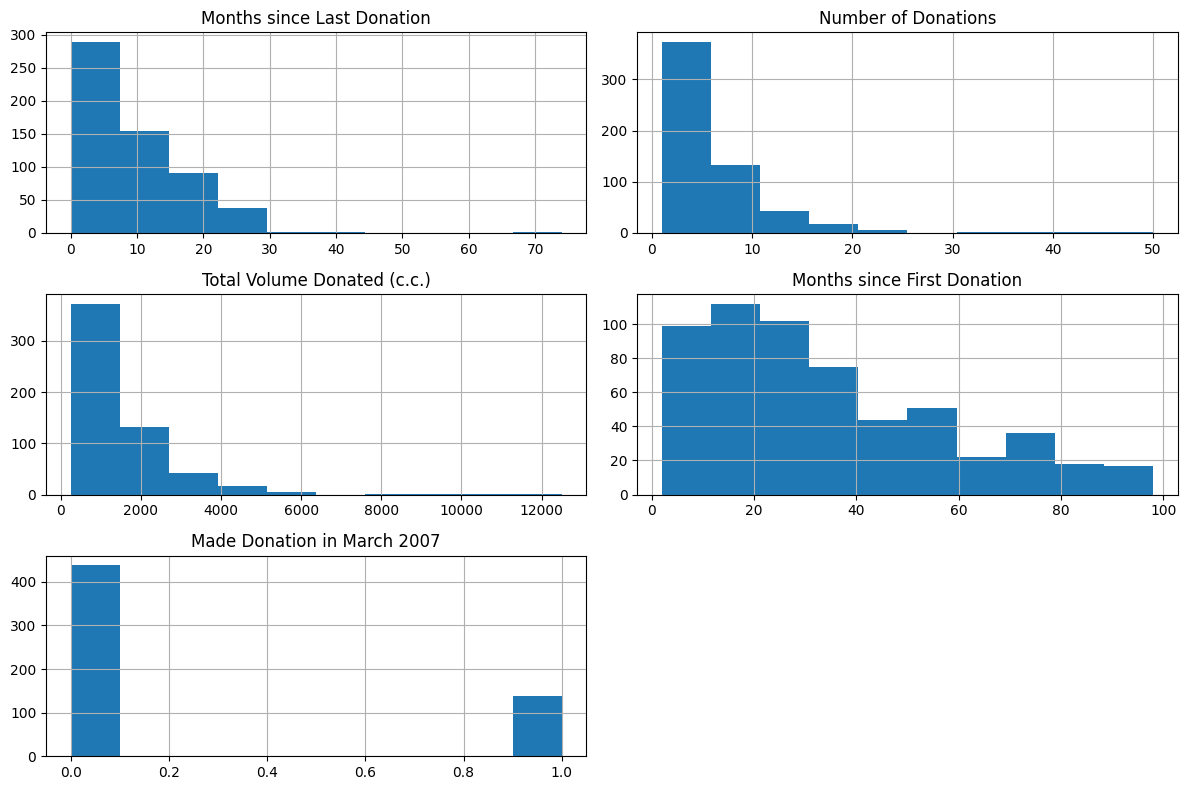

In [ ]:
df.hist(figsize=(12, 8))
plt.tight_layout()
plt.show()


Target distribution



In [ ]:
# Check the distribution of our target variable to see if there is any class imbalance
df['Made Donation in March 2007'].value_counts()

,count
Made Donation in March 2007,
0,438
1,138


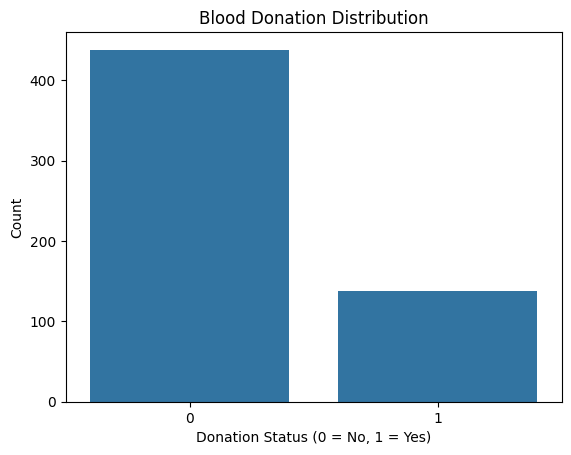

In [ ]:
# Visualize the distribution of the target variable using a countplot
sns.countplot(x='Made Donation in March 2007', data=df)
plt.title('Blood Donation Distribution')
plt.xlabel('Donation Status (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

# Bivariate analysis
Bivariate analysis examines the relationship between two variables.

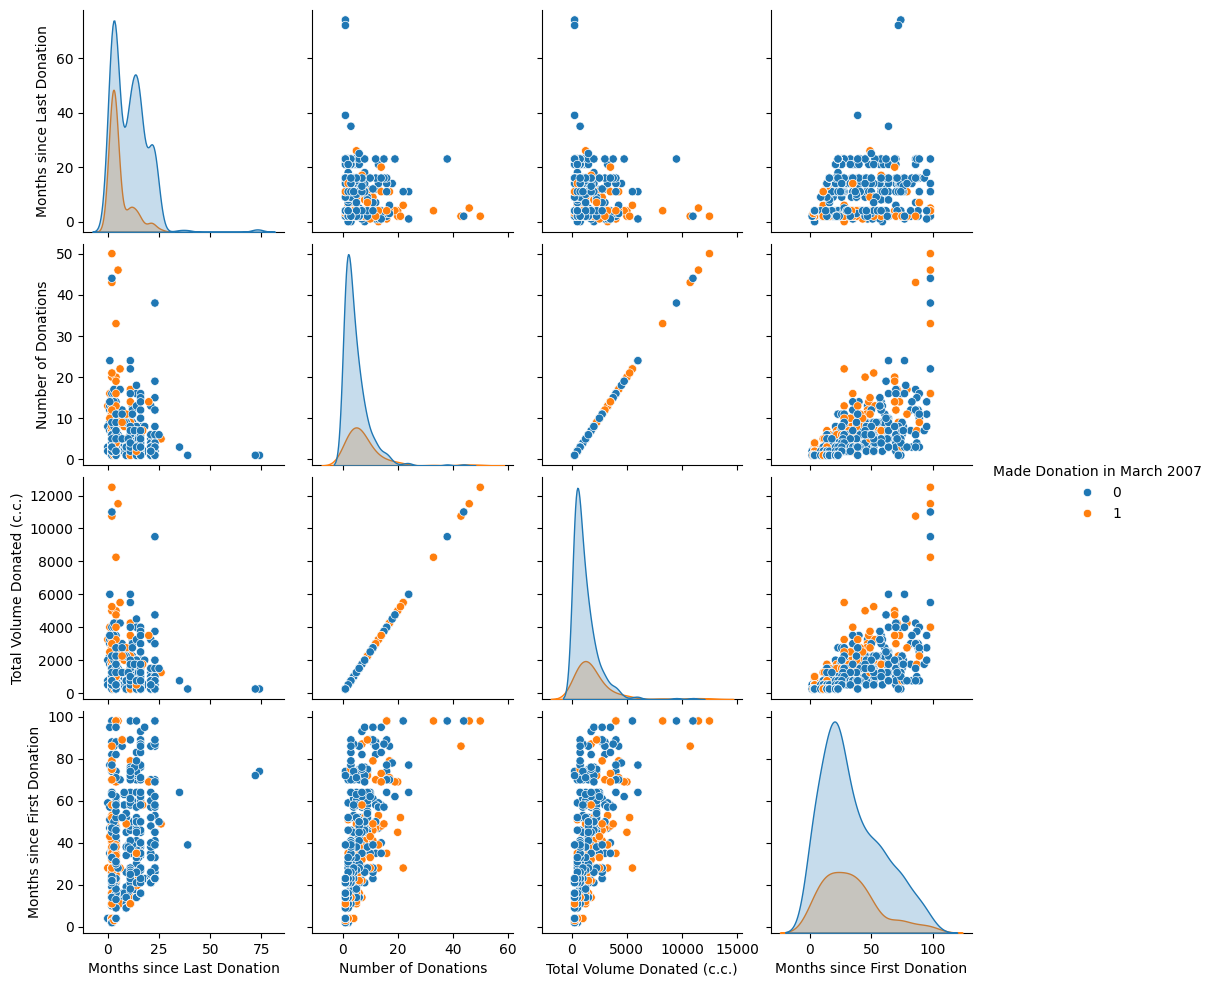

In [ ]:
# Generate a pairplot grid to examine pairwise relationships among all variables, colored by target class
sns.pairplot(df, hue='Made Donation in March 2007')
plt.show()

Correlation analysis

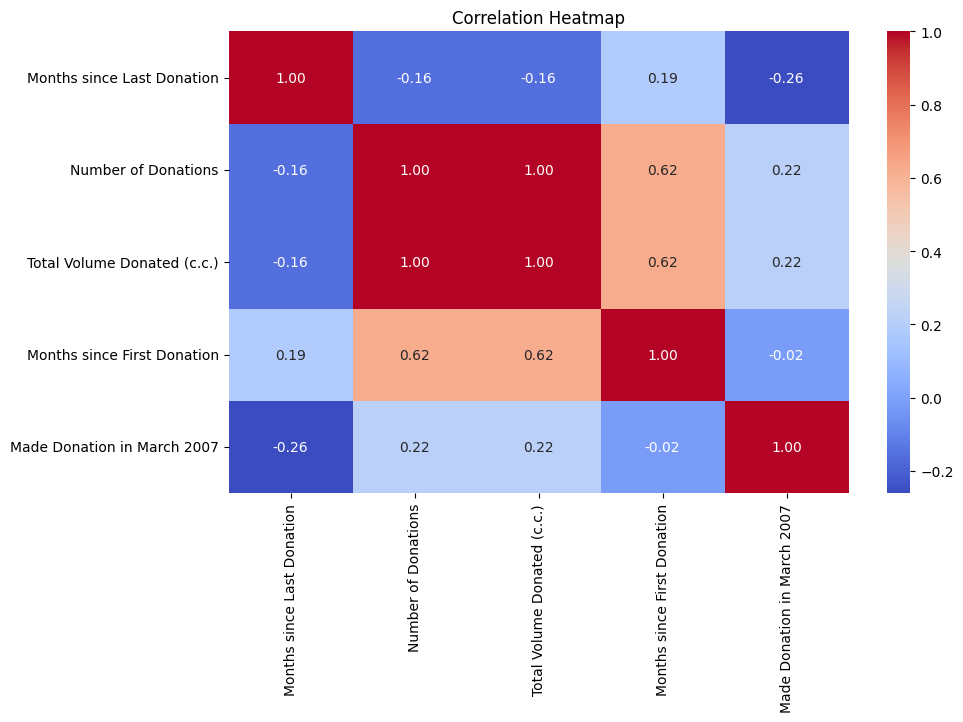

In [ ]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

Observations:
- Number of Donations and Total Volume Donated have a correlation of 1.00.
- Number of Donations and Months since First Donation have a positive correlation of approximately 0.62.
- Months since Last Donation has a negative correlation of approximately -0.26 with the target.
- Number of Donations and Total Volume Donated have a positive correlation of approximately 0.22 with the target.
Conclusion: Correlation helps identify relationships between numerical features. However, correlation does not imply causation.

## 8. Outlier analysis
Boxplots were used to identify potential outliers.

In [ ]:
plt.figure(figsize=(12, 8))

for i, col in enumerate(X.columns, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

NameError: name 'lt' is not defined

Observation:

Potential outliers were observed in:
- Months since Last Donation
- Number of Donations
- Total Volume Donated
These values were not removed blindly because they may represent genuine donor behaviour.

## 9. Feature and target separation

In [ ]:
X = df.drop('Made Donation in March 2007', axis=1)

y = df['Made Donation in March 2007']

Explanation:
- X contains the independent variables (features).
- y contains the dependent variable (target).

## 10. Skewness analysis and transformation
Skewness measures the asymmetry of a data distribution.

In [ ]:
# Calculate and check skewness scores for all numerical features
df.skew(numeric_only=True)

,0
Months since Last Donation,2.071107
Number of Donations,3.503331
Total Volume Donated (c.c.),3.503331
Months since First Donation,0.767706
Made Donation in March 2007,1.223427


Apply log transformation

In [ ]:
# Create a copy of the original dataframe before applying logarithmic transformation
df_transformed = df.copy()

# Define columns with high skewness to apply log transformation
skewed_columns = [
    'Months since Last Donation',
    'Number of Donations',
    'Total Volume Donated (c.c.)'
]

# Apply natural logarithm log1p (log(x + 1)) to handle zero values safely
for col in skewed_columns:
    df_transformed[col] = np.log1p(df_transformed[col])

Check the new skewness:

In [ ]:
# Re-verify the skewness scores of the transformed columns to confirm reduction
df_transformed[skewed_columns].skew()

,0
Months since Last Donation,-0.017768
Number of Donations,0.446914
Total Volume Donated (c.c.),0.109565


## 11. Train-test split

In [ ]:
# Redeclare features and target
X = df.drop('Made Donation in March 2007', axis=1)
y = df['Made Donation in March 2007']

# Split the dataset into training (80%) and testing sets (20%) using stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y # Stratification ensures same proportion of classes in train and test splits
)

Explanation:
- 80% of the data is used for training.
- 20% of the data is used for testing.
- random_state=42 ensures reproducibility.
- stratify=y maintains the target class proportions in both sets.

## 12. Feature scaling
StandardScaler was used to standardize the numerical features.

In [ ]:
# Initialize a standard scaler to scale the numerical features
scaler = StandardScaler()

# Fit on training data and transform both train and test sets to prevent data leakage
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Formula:

z = x- mu/sigma

Where:
- \(x\) = Original value
- \(\mu\) = Mean
- \(\sigma\) = Standard deviation
Why scaling?

Scaling brings numerical features to a comparable scale. It is useful for algorithms such as Logistic Regression, KNN and SVM.

For tree-based algorithms such as Decision Tree and Random Forest, scaling is generally not required.
13. Model building

In [ ]:
# Print shapes of train and test datasets to verify the split was correct
print("X_train:", X_train_scaled.shape)
print("X_test:", X_test_scaled.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (460, 4)
X_test: (116, 4)
y_train: (460,)
y_test: (116,)


## 13. Model building
Seven classification algorithms were implemented and evaluated.

## 1. Logistic Regression

Definition: Logistic Regression is a supervised classification algorithm that predicts the probability of a class using a logistic function.

Example: Predicting whether a person will donate blood or not.

In [ ]:
# Initialize and fit the Logistic Regression model using scaled features
lr = LogisticRegression()
lr.fit(X_train_scaled, y_train)

LogisticRegression()

In [ ]:
# Generate predictions for Logistic Regression using the test set
y_pred_lr = lr.predict(X_test_scaled)

In [ ]:
y_pred_lr

array([0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0])

In [ ]:
# Print the basic classification accuracy score of the Logistic Regression model
print("Accuracy:", accuracy_score(y_test, y_pred_lr))

Accuracy: 0.7758620689655172


In [ ]:
# Display detailed classification metrics (precision, recall, f1-score) for Logistic Regression
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.79      0.97      0.87        88
           1       0.62      0.18      0.28        28

    accuracy                           0.78       116
   macro avg       0.71      0.57      0.57       116
weighted avg       0.75      0.78      0.73       116



## 2. K-Nearest Neighbors (KNN)

Definition: KNN predicts the class of a new data point based on the majority class among its nearest neighbours.

In [ ]:
# Initialize and fit a K-Nearest Neighbors classifier (K=5)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

KNeighborsClassifier()

In [ ]:
# Make predictions with the KNN model using scaled features
y_pred_knn = knn.predict(X_test_scaled)

In [ ]:
y_pred_knn

array([0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0])

In [ ]:
# Output model accuracy and a full classification report for the KNN classifier
print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print(classification_report(y_test, y_pred_knn))

Accuracy: 0.75
              precision    recall  f1-score   support

           0       0.79      0.92      0.85        88
           1       0.46      0.21      0.29        28

    accuracy                           0.75       116
   macro avg       0.62      0.57      0.57       116
weighted avg       0.71      0.75      0.71       116



## 3. Decision Tree

Definition: Decision Tree is a supervised learning algorithm that makes predictions using a tree-like structure of decision rules.

In [ ]:
# Initialize and train a baseline Decision Tree Classifier
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [ ]:
# Make predictions on the unscaled test set using our Decision Tree model
y_pred_dt = dt.predict(X_test)

In [ ]:
y_pred_dt

array([0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1,
       0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1,
       0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1])

In [ ]:
# Display metrics and classification performance of the Decision Tree model
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))

Accuracy: 0.6293103448275862
              precision    recall  f1-score   support

           0       0.76      0.75      0.75        88
           1       0.24      0.25      0.25        28

    accuracy                           0.63       116
   macro avg       0.50      0.50      0.50       116
weighted avg       0.63      0.63      0.63       116



## 4. Random Forest

Definition: Random Forest is an ensemble learning algorithm that combines multiple decision trees to improve prediction performance.

In [ ]:
# Initialize and train a Random Forest Classifier using 100 decision trees
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [ ]:
# Generate predictions for the Random Forest model on the test set
y_pred_rf = rf.predict(X_test)

In [ ]:
y_pred_rf

array([0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0])

In [ ]:
# Output performance metrics for the standard Random Forest model
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

Accuracy: 0.75
              precision    recall  f1-score   support

           0       0.81      0.88      0.84        88
           1       0.48      0.36      0.41        28

    accuracy                           0.75       116
   macro avg       0.64      0.62      0.62       116
weighted avg       0.73      0.75      0.74       116



## 5. Support Vector Machine (SVM)

Definition: SVM is a supervised learning algorithm that finds an optimal decision boundary to separate different classes.

In [ ]:
# Initialize and train a Support Vector Classifier using Radial Basis Function (RBF) kernel
svm = SVC(kernel='rbf')
svm.fit(X_train_scaled, y_train)

SVC()

In [ ]:
# Generate predictions for the Support Vector Classifier using scaled test set
y_pred_svm = svm.predict(X_test_scaled)

In [ ]:
y_pred_svm

array([0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0])

In [ ]:
# Print metrics for the Support Vector Classifier model
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print(classification_report(y_test, y_pred_svm))

Accuracy: 0.7672413793103449
              precision    recall  f1-score   support

           0       0.78      0.97      0.86        88
           1       0.57      0.14      0.23        28

    accuracy                           0.77       116
   macro avg       0.68      0.55      0.55       116
weighted avg       0.73      0.77      0.71       116



## 6. Gaussian Naive Bayes

Definition: Naive Bayes is a probabilistic classification algorithm based on Bayes' theorem. Gaussian Naive Bayes assumes that features follow a Gaussian distribution within each class.

In [ ]:
# Initialize and fit a Naive Bayes (Gaussian NB) classifier on the features
beyond_nb = GaussianNB()
beyond_nb.fit(X_train, y_train)

GaussianNB()

In [ ]:
# Get predictions from the Naive Bayes model
y_pred_nb = beyond_nb.predict(X_test)

In [ ]:
y_pred_nb

array([0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0])

In [ ]:
# Print classification results for the Naive Bayes model
print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print(classification_report(y_test, y_pred_nb))

Accuracy: 0.7672413793103449
              precision    recall  f1-score   support

           0       0.79      0.94      0.86        88
           1       0.55      0.21      0.31        28

    accuracy                           0.77       116
   macro avg       0.67      0.58      0.58       116
weighted avg       0.73      0.77      0.73       116



## 7. XGBoost

Definition: XGBoost is an ensemble learning algorithm based on gradient boosting. It builds trees sequentially, with each new tree attempting to correct errors made by previous trees.

In [ ]:
# Install the XGBoost package to use gradient boosting classifiers
!pip install xgboost

In [ ]:
# Initialize and train an XGBoost Classifier
xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
    eval_metric='logloss'
)
xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:
# Obtain testing set predictions using our XGBoost model
y_pred_xgb = xgb.predict(X_test)

In [ ]:
y_pred_xgb

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0])

In [ ]:
# Print metrics evaluating the performance of the XGBoost classifier
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))

Accuracy: 0.7327586206896551
              precision    recall  f1-score   support

           0       0.79      0.88      0.83        88
           1       0.42      0.29      0.34        28

    accuracy                           0.73       116
   macro avg       0.61      0.58      0.59       116
weighted avg       0.70      0.73      0.71       116



## 14. Model evaluation
Classification models were evaluated using the following metrics.



Accuracy  -	Overall percentage of correct predictions

Precision  -	How many predicted positive cases were actually positive

Recall	- How many actual positive cases were correctly identified

F1-score	-Harmonic mean of precision and recall

ROC-AUC  -	Measures the model's ability to distinguish between classes



Evaluation code

In [ ]:
# Create a dictionary of the predictions generated by all models trained so far
models = {
    'Logistic Regression': y_pred_lr,
    'KNN': y_pred_knn,
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf,
    'SVM': y_pred_svm,
    'Naive Bayes': y_pred_nb,
    'XGBoost': y_pred_xgb
}

# Initialize lists to store computed metrics for comparison
results = []

# Loop through each model to calculate Accuracy, Precision, Recall and F1 score
for name, pred in models.items():
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1 Score': f1_score(y_test, pred, zero_division=0)
    })

# Convert results to a pandas DataFrame and sort models by F1-Score
comparison_df = pd.DataFrame(results)
comparison_df.sort_values(by='F1 Score', ascending=False)

,Model,Accuracy,Precision,Recall,F1 Score
3,Random Forest,0.750000,0.476190,0.357143,0.408163
6,XGBoost,0.732759,0.421053,0.285714,0.340426
5,Naive Bayes,0.767241,0.545455,0.214286,0.307692
1,KNN,0.750000,0.461538,0.214286,0.292683
0,Logistic Regression,0.775862,0.625000,0.178571,0.277778
2,Decision Tree,0.629310,0.241379,0.250000,0.245614
4,SVM,0.767241,0.571429,0.142857,0.228571


Observation:
- Logistic Regression achieved the highest initial accuracy of 77.59%.
- Random Forest achieved the highest F1-score for the donation class.
- Random Forest also achieved the highest recall among the initial seven models.
- Decision Tree showed the weakest overall performance based on the reported F1-score.
Important: The majority-class baseline accuracy is 76.04%. Therefore, accuracy by itself is not a good measure of success for this imbalanced dataset.

## 15. Confusion matrix
A confusion matrix helps us understand correct and incorrect predictions.

For your original Random Forest:

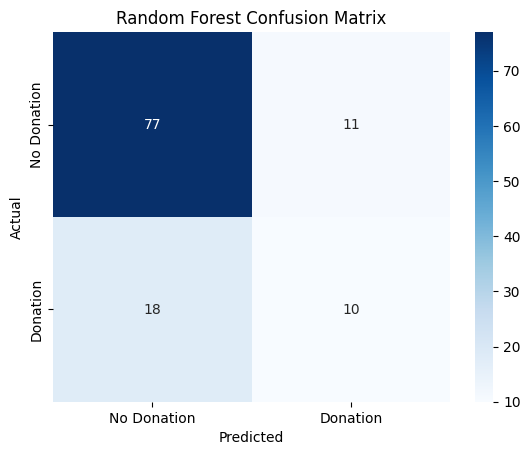

In [ ]:
from sklearn.metrics import confusion_matrix


# Compute the confusion matrix for the Random Forest model
cm = confusion_matrix(y_test, y_pred_rf)

# Plot confusion matrix using seaborn heatmap
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Donation', 'Donation'],
    yticklabels=['No Donation', 'Donation']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest Confusion Matrix')
plt.show()

Interpretation:
- True Negative: 77
- False Positive: 11
- False Negative: 18
- True Positive: 10
The model correctly identified 10 donors out of 28 actual donors.

## 16. Classification report

In [ ]:
# Print classification summary for the baseline Random Forest model
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.81      0.88      0.84        88
           1       0.48      0.36      0.41        28

    accuracy                           0.75       116
   macro avg       0.64      0.62      0.62       116
weighted avg       0.73      0.75      0.74       116



## 17. Handling class imbalance
The dataset contains more non-donors than donors. Therefore, different techniques were tested to handle class imbalance.
Experiment 1: Class weight balancing

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Initialize and train Random Forest with balanced class weights to address minority class target
rf_balanced = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

rf_balanced.fit(X_train, y_train)

# Make predictions
y_pred_balanced = rf_balanced.predict(X_test)

Explanation: class_weight='balanced' automatically gives higher importance to the minority class during model training.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# Evaluate the balanced Random Forest model using confusion matrix and report
print(confusion_matrix(y_test, y_pred_balanced))
print(classification_report(y_test, y_pred_balanced))

[[75 13]
 [18 10]]
              precision    recall  f1-score   support

           0       0.81      0.85      0.83        88
           1       0.43      0.36      0.39        28

    accuracy                           0.73       116
   macro avg       0.62      0.60      0.61       116
weighted avg       0.72      0.73      0.72       116



Experiment 2: SMOTE

SMOTE stands for Synthetic Minority Over-sampling Technique.

It generates synthetic samples for the minority class to balance the training dataset.

In [ ]:
# Install the imbalanced-learn library to implement oversampling methods like SMOTE
!pip install imbalanced-learn

In [ ]:
from imblearn.over_sampling import SMOTE

# Initialize SMOTE to balance our dataset classes
smote = SMOTE(random_state=42)

# Apply oversampling to features and targets in training set
X_train_smote, y_train_smote = smote.fit_resample(
    X_train, y_train
)

# Print the balanced class distribution counts to verify results
print(y_train_smote.value_counts())

Made Donation in March 2007
0    350
1    350
Name: count, dtype: int64


Train the model:

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Initialize and train Random Forest Classifier using the SMOTE balanced training data
rf_smote = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_smote.fit(X_train_smote, y_train_smote)

# Generate predictions for SMOTE Random Forest
y_pred_smote = rf_smote.predict(X_test)

Important: SMOTE was applied only to the training data. The test data was kept unchanged.

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Display overall metrics for the SMOTE balanced Random Forest model
print("Accuracy:", accuracy_score(y_test, y_pred_smote))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_smote))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_smote))

Accuracy: 0.6810344827586207

Confusion Matrix:
[[67 21]
 [16 12]]

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.76      0.78        88
           1       0.36      0.43      0.39        28

    accuracy                           0.68       116
   macro avg       0.59      0.59      0.59       116
weighted avg       0.70      0.68      0.69       116




Conclusion:
- Class weighting did not improve donor recall.
- SMOTE increased donor recall from 0.36 to 0.43.
- However, SMOTE reduced accuracy and precision.
- The original Random Forest achieved the highest donor F1-score of these three experiments.
This shows that balancing techniques do not always improve every evaluation metric.

This shows that balancing techniques do not always improve every evaluation metric.

## 18. Hyperparameter tuning
Hyperparameter tuning was performed to find better model configurations.


Random Forest tuning

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# Define the hyperparameter search grid for Random Forest
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

# Perform a 5-fold cross validation grid search, optimizing on F1-Score
grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid.fit(X_train, y_train)

# Display hyperparameter optimization results
print("Best Parameters:", grid.best_params_)
print("Best CV F1 Score:", grid.best_score_)

Best Parameters: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
Best CV F1 Score: 0.5068742368742368


Evaluate tuned Random Forest

In [ ]:
# Save the best model estimator returned from our F1-score Grid Search optimization
best_rf = grid.best_estimator_

In [ ]:
# Make predictions with the F1-optimized Random Forest model
y_pred_tuned = best_rf.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Output model evaluation results for the F1-optimized model
print("Accuracy:", accuracy_score(y_test, y_pred_tuned))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

Accuracy: 0.7672413793103449

Confusion Matrix:
[[80  8]
 [19  9]]

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.91      0.86        88
           1       0.53      0.32      0.40        28

    accuracy                           0.77       116
   macro avg       0.67      0.62      0.63       116
weighted avg       0.74      0.77      0.75       116



Observation: Hyperparameter tuning improved accuracy and precision compared with the original Random Forest, but donor recall decreased slightly.

In [ ]:
from sklearn.metrics import roc_auc_score

# Predict probabilities of the positive class using the fitted best_rf model
y_prob_rf = best_rf.predict_proba(X_test)[:, 1]

# Calculate and print ROC-AUC performance
roc_auc = roc_auc_score(y_test, y_prob_rf)
print("Random Forest ROC-AUC:", roc_auc)

Random Forest ROC-AUC: 0.6473214285714287


original Random Forest ROC-AUC: 0.647

This indicates that the model has some ability to distinguish donors from non-donors, but its discrimination performance needs improvement.

ROC-AUC interpretation:
Score	General interpretation
0.50	-No better than random ranking

0.60–0.70	Weak discrimination

0.70–0.80	Acceptable discrimination

0.80–0.90	Good discrimination

0.90–1.00	Excellent discrimination

## 20. Final model selection
After comparing the seven algorithms, class-balancing techniques and hyperparameter-tuning experiments, the original Random Forest is the current preferred model when prioritizing donor F1-score.

Why?
- It achieved the highest donor F1-score of 0.41.
- It achieved the highest donor recall among the original seven algorithms.
- It performed slightly better than the tuned Random Forest on donor F1-score and recall.
- SMOTE improved recall, but reduced precision and accuracy.
my tuned Random Forest achieved the highest reported accuracy of 76.72%, but its donor F1-score was slightly lower.

## Final model choice: Original Random Forest

## 21. Save the final model
Because  Random Forest was trained using log-transformed features, save the model along with the feature names and transformation details.

In [ ]:
import joblib

model_artifacts = {
    'model': rf,
    'features': list(X_train.columns),
    'log_features': [
        'Months since Last Donation',
        'Number of Donations',
        'Total Volume Donated (c.c.)'
    ]
}

joblib.dump(
    model_artifacts,
    'blood_donation_model.pkl'
)

['blood_donation_model.pkl']

In [ ]:
model_artifacts = joblib.load('blood_donation_model.pkl')

loaded_model = model_artifacts['model']

print("Model loaded successfully")

Model loaded successfully


# 22 .Conclusion

The Blood Donation Prediction project was developed using supervised Machine Learning classification algorithms to predict whether an individual would donate blood in March 2007 based on their previous donation history.

The project involved data cleaning, exploratory data analysis, feature transformation, feature scaling, model training and evaluation.

Seven classification algorithms were implemented: Logistic Regression, K-Nearest Neighbors, Decision Tree, Random Forest, Support Vector Machine, Gaussian Naive Bayes and XGBoost.

Different techniques were also explored to handle class imbalance, including class weighting and SMOTE. Hyperparameter tuning was performed to investigate improvements in model performance.

Among the initial classification models, Random Forest achieved the best F1-score for the donor class. The original Random Forest achieved 75% accuracy, 48% precision, 36% recall and a 0.41 F1-score for the donation class.

The results demonstrate that predicting potential blood donors is challenging because of class imbalance and the limited dataset size. Although the model provides useful predictions, further improvements are required to increase donor detection performance.

This project provided practical experience in data preprocessing, exploratory data analysis, classification algorithms, handling imbalanced datasets and model evaluation.

## 23. Project limitations and future improvements
Limitations:
1. The dataset contains only 576 records.
2. The target variable is imbalanced.
3. The model has relatively low recall for actual donors.
4. The model may not generalize well to different donor populations.
5. The available features provide limited information about donor behaviour.

Future improvements:
- Collect more donor records.
- Explore additional relevant donor features.
- Perform more robust cross-validation.
- Experiment with probability-threshold optimization.
- Evaluate additional ensemble techniques.
- Improve minority-class prediction performance.

## # Model Comparison Report – Blood Donation Prediction

## Introduction

Multiple Machine Learning classification algorithms were implemented to predict whether an individual would donate blood in March 2007.

The following seven algorithms were evaluated:

1. Logistic Regression
2. K-Nearest Neighbors (KNN)
3. Decision Tree
4. Random Forest
5. Support Vector Machine (SVM)
6. Gaussian Naive Bayes
7. XGBoost

## Model Performance Comparison

| Model | Accuracy | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|
| Logistic Regression | 77.59% | 62.50% | 17.86% | 27.78% |
| KNN | 75.00% | 46.15% | 21.43% | 29.27% |
| Decision Tree | 62.93% | 24.14% | 25.00% | 24.56% |
| Random Forest | 75.00% | 47.62% | 35.71% | 40.82% |
| SVM | 76.72% | 57.14% | 14.29% | 22.86% |
| Gaussian Naive Bayes | 76.72% | 54.55% | 21.43% | 30.77% |
| XGBoost | 73.28% | 42.11% | 28.57% | 34.04% |

## Model Analysis

**Logistic Regression:** Achieved the highest initial accuracy of 77.59% and precision of 62.50%, but its donor recall was low.

**KNN:** Achieved moderate accuracy but had relatively low recall for the donation class.

**Decision Tree:** Achieved the lowest accuracy among the seven models.

**Random Forest:** Achieved the highest F1-score and recall for the donation class among the initial seven algorithms.

**SVM:** Achieved good accuracy and precision but had low donor recall.

**Gaussian Naive Bayes:** Achieved 76.72% accuracy but showed lower donor recall than Random Forest.

**XGBoost:** Achieved moderate performance, but its initial donor prediction performance was lower than Random Forest.

## Additional Experiments

To improve model performance, additional experiments were performed.

- Class weight balancing using Random Forest.
- SMOTE oversampling.
- Random Forest hyperparameter tuning using GridSearchCV.
- XGBoost hyperparameter tuning using GridSearchCV.

The original Random Forest achieved a donor F1-score of 0.41, while SMOTE Random Forest achieved a donor recall of 0.43. The tuned Random Forest achieved 76.72% accuracy.

## Final Model Selection

The original Random Forest was selected as the preferred model based on its donor-class F1-score and recall among the initial seven algorithms.

### Final Model Performance

| Metric | Score |
|---|---:|
| Accuracy | 75.00% |
| Precision | 47.62% |
| Recall | 35.71% |
| F1-score | 40.82% |
| ROC-AUC | 0.647 |

## Recommendation for Production

Random Forest is selected as the preferred candidate for further development because it provides a better balance between precision and recall for identifying potential blood donors among the initial models.

However, its donor recall is relatively low. Therefore, it should not be deployed for real-world donor targeting without further validation and improvement.

Additional data collection, cross-validation, threshold optimization and performance evaluation are recommended before production deployment.

## Conclusion

Random Forest provided the best initial balance of donor-class precision and recall among the seven evaluated algorithms. Model selection was based on multiple evaluation metrics rather than accuracy alone.

# Report on Challenges Faced – Blood Donation Prediction

During the development of the Blood Donation Prediction project, several challenges were encountered during data preprocessing, exploratory data analysis and model development.

The following challenges and techniques were addressed.

### 1. Unnecessary Columns

**Challenge:** The dataset contained an additional record ID column that was not useful for prediction.

**Technique Used:** Column removal using Pandas `drop()`.

**Reason:** The record ID does not contain meaningful predictive information.

### 2. Class Imbalance

**Challenge:** The dataset contained more non-donors than donors.

- No Donation: 438 records (76.04%)
- Donation: 138 records (23.96%)

**Techniques Used:**
- Class weight balancing.
- SMOTE (Synthetic Minority Over-sampling Technique).

**Reason:** These techniques were tested to give greater importance to the minority class and improve donor prediction.

**Observation:** SMOTE improved donor recall from 35.71% to 42.86%, but reduced overall accuracy and precision.

### 3. Skewed Data Distribution

**Challenge:** Some numerical features had highly right-skewed distributions.

**Technique Used:** Log transformation using NumPy `log1p()`.

**Reason:** Log transformation reduced the skewness of numerical features and made their distributions more balanced.

### 4. Outliers

**Challenge:** Boxplots indicated potential outliers in Months since Last Donation, Number of Donations and Total Volume Donated.

**Technique Used:** Boxplot visualization and statistical analysis.

**Reason:** Outliers were investigated but not removed blindly because they could represent genuine donor behaviour.

### 5. Feature Scaling

**Challenge:** Numerical features had different ranges.

**Technique Used:** StandardScaler.

**Reason:** Scaling standardized the numerical features and helped distance-based and optimization-based algorithms such as KNN, SVM and Logistic Regression.

### 6. Feature Correlation

**Challenge:** Number of Donations and Total Volume Donated showed a correlation of 1.00.

**Technique Used:** Correlation heatmap.

**Reason:** Correlation analysis helped identify potentially redundant features and understand relationships between variables.

### 7. Model Performance

**Challenge:** Different algorithms produced different accuracy, precision, recall and F1-score values.

**Technique Used:** Multiple classification algorithms and performance evaluation metrics.

**Reason:** Comparing multiple algorithms helped identify a suitable model instead of depending on a single algorithm.

### 8. Hyperparameter Tuning

**Challenge:** Initial models did not provide the desired prediction performance.

**Technique Used:** GridSearchCV.

**Reason:** Hyperparameter tuning tested different parameter combinations using cross-validation to find better model configurations.

### 9. Evaluation of Imbalanced Classification

**Challenge:** Some models achieved reasonable accuracy but failed to identify actual donors effectively.

**Technique Used:** Confusion matrix, classification report, precision, recall, F1-score and ROC-AUC.

**Reason:** These metrics provided a better understanding of model performance, especially for the minority donation class.

## Conclusion

The project involved several practical challenges related to data quality, skewness, outliers, class imbalance and model performance.

Different preprocessing techniques, balancing methods and classification algorithms were explored to address these challenges.

The experiments demonstrated the importance of selecting appropriate evaluation metrics and comparing multiple approaches before choosing a final Machine Learning model.